# Experiment A &mdash; Target Matching in GP Bayesian Optimization

Benchmark: **Forrester 1D** &mdash; $f(x) = (6x-2)^2\sin(12x-4)$ on $[0,1]$.

We study the target-matching problem

$$
\min_{x \in \mathcal{X}} \; |f(x) - T|,
$$

and compare **two ways of injecting the target $T$ into the BO loop**. The two
methods do *not* merely differ by an acquisition function: **they differ by the
statistical object their Gaussian process models.**

**RIGHT &mdash; Separation of Concerns.** The GP models the raw, unknown function
$f$. The target enters *only* through the acquisition,

$$
\alpha_{\mathrm{RIGHT}}(x) \;=\; -\,|\mu_f(x) - T| \;+\; \sqrt{\beta}\,\sigma_f(x).
$$

**WRONG &mdash; target baked into the surrogate.** The GP is trained directly on
the transformed observations $|y_{\mathrm{obs}} - T|$, and the acquisition is a
lower-confidence bound on that surrogate,

$$
\alpha_{\mathrm{WRONG}}(x) \;=\; -\,\mu_{|f-T|}(x) \;+\; \sqrt{\beta}\,\sigma_{|f-T|}(x).
$$

The central thesis of Separation of Concerns is that **the target belongs in the
decision rule (the acquisition), not in the learning target of the GP**. RIGHT
keeps the surrogate a faithful model of $f$; WRONG forces it to fit the *kinked*
function $|f - T|$, whose derivative is discontinuous at every target match.

This notebook is organised as:

0. **Imports, paths and configuration** &mdash; reproducible setup and sanity checks.
1. **Geometry of the target-matching problem** &mdash; what each method models.
2. **Mechanism on one seed** &mdash; posteriors and acquisitions over iterations.
3. **Optimization performance across seeds** &mdash; convergence, tails, paired tests.
4. **Probabilistic model diagnostics** &mdash; NLPD, coverage, residuals, PIT, QQ.
5. **Summary of findings** &mdash; optimization vs calibration, and the SoC reading.

## 0. Imports, paths and configuration

### 0.1 Imports and plotting style

All figures are collected in a global `FIGURES` dictionary as they are produced
and written to disk **once** in the final *"Save all figures"* cell &mdash; no
figure is saved mid-notebook, and none is closed before that cell.

In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path
from typing import Any, Iterable, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import torch

REPO_ROOT = Path(
    "/users/eleves-b/2023/benjamin.wilhelm/gpbo-separation-of-concerns/"
    "bayesian-optimization-separation-concerns"
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

from common.serialization import load_json          # noqa: E402
from benchmarks import BENCHMARK_REGISTRY, build_benchmark  # noqa: E402

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Canonical colours / labels for the two compared methods.
METHOD_STYLE = {
    "right_target_matching_ucb": {"label": "RIGHT (GP on f)",     "color": "#1f77b4"},
    "wrong_gp_on_abs_lcb":       {"label": "WRONG (GP on |f-T|)", "color": "#d62728"},
}

def style_for(method: str) -> dict:
    """Style for a method, with a neutral fallback for unknown names."""
    return METHOD_STYLE.get(method, {"label": method, "color": None})

# Global figure registry: every plotting cell does FIGURES["<name>"] = fig.
FIGURES: dict[str, plt.Figure] = {}

def add_figure(name: str, fig: plt.Figure) -> plt.Figure:
    """Register `fig` under `name` for the final batch-save cell."""
    if name in FIGURES:
        print(f"[warn] overwriting already-registered figure '{name}'")
    FIGURES[name] = fig
    return fig

### 0.2 Run directory and benchmark selection

This is the **only** block to edit when switching runs or benchmarks. Newer runs
nest the processed outputs under a per-benchmark sub-directory
(`processed/aggregate/<benchmark>/` and `processed/per_seed/<benchmark>/`); the
paths below follow that convention.

In [2]:
RUN_DIR = Path("results/exp_a_target_matching/runs/2026-05-20_19-56-19_forrester_1d_full")
BENCHMARK = "forrester_1d"

AGG_DIR = RUN_DIR / "processed" / "aggregate" / BENCHMARK
PER_SEED_DIR = RUN_DIR / "processed" / "per_seed" / BENCHMARK
FIG_DIR = RUN_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

for label, path in [("run", RUN_DIR), ("aggregate", AGG_DIR), ("per_seed", PER_SEED_DIR)]:
    print(f"{label:>10s}: {path}  (exists={path.exists()})")
print(f"{'figures':>10s}: {FIG_DIR}")

       run: results/exp_a_target_matching/runs/2026-05-20_19-56-19_forrester_1d_full  (exists=True)
 aggregate: results/exp_a_target_matching/runs/2026-05-20_19-56-19_forrester_1d_full/processed/aggregate/forrester_1d  (exists=True)
  per_seed: results/exp_a_target_matching/runs/2026-05-20_19-56-19_forrester_1d_full/processed/per_seed/forrester_1d  (exists=True)
   figures: results/exp_a_target_matching/runs/2026-05-20_19-56-19_forrester_1d_full/figures


### 0.3 Load config, metadata and aggregate files

We load `config.json` / `metadata.json`, the per-seed processed records, and
whichever aggregate files are present. Aggregate files are loaded into a single
`agg` dict and missing ones are tolerated (set to `None`) so the notebook still
runs on partial runs. We also detect whether per-point posterior **predictions**
were stored, since some runs disable them to save space.

In [3]:
config = load_json(RUN_DIR / "config.json")
metadata = load_json(RUN_DIR / "metadata.json")

# ---- aggregate files (tolerate missing ones) ----
AGG_FILES = [
    "convergence_curves",
    "calibration_curves",
    "final_performance",
    "calibration_summary",
    "statistical_tests",
]
agg: dict[str, Optional[dict]] = {}
for name in AGG_FILES:
    p = AGG_DIR / f"{name}.json"
    agg[name] = load_json(p) if p.exists() else None

# ---- per-seed records ----
def load_all_per_seed(per_seed_dir: Path) -> list[dict]:
    """Load every seed_*_processed.json under `per_seed_dir`, sorted by name."""
    files = sorted(per_seed_dir.glob("seed_*_processed.json"))
    if not files:
        raise FileNotFoundError(f"No processed per-seed files under {per_seed_dir}")
    return [load_json(p) for p in files]

def method_names(seed_record: dict) -> list[str]:
    """Method keys in the order they appear in a per-seed record."""
    return list(seed_record["methods"].keys())

all_seeds = load_all_per_seed(PER_SEED_DIR)
seed0 = all_seeds[0]
methods = method_names(seed0)

# ---- frequently used scalars ----
T = float(config["target"])
BETA = float(config["beta"])

# ---- benchmark object (used for geometry, posterior reconstruction, PIT/QQ) ----
benchmark = build_benchmark(config)
DIM = int(benchmark.dim)

# ---- were per-point posterior predictions stored? ----
PREDICTIONS_AVAILABLE = any(
    c.get("predictions") for c in seed0["methods"][methods[0]]["calibrations"]
)

print(f"loaded {len(all_seeds)} per-seed records | methods = {methods}")
print(f"aggregate files present: {[k for k, v in agg.items() if v is not None]}")
print(f"benchmark = {BENCHMARK} (dim={DIM}) | target T = {T:g} | beta = {BETA:g}")
print(f"per-point predictions stored: {PREDICTIONS_AVAILABLE}")

loaded 100 per-seed records | methods = ['right_target_matching_ucb', 'wrong_gp_on_abs_lcb']
aggregate files present: ['convergence_curves', 'calibration_curves', 'final_performance', 'calibration_summary', 'statistical_tests']
benchmark = forrester_1d (dim=1) | target T = 0 | beta = 2
per-point predictions stored: True


In [4]:
# Protocol summary table (read straight from config / metadata).
test_grid_cfg   = config.get("test_grid", {})
calibration_cfg = config.get("calibration", {})
aggregate_cfg   = config.get("aggregate", {})

setup = {
    "experiment":          config.get("experiment"),
    "benchmark":           config.get("benchmark"),
    "tag":                 config.get("tag"),
    "timestamp_utc":       metadata.get("timestamp_utc"),
    "git_commit":          metadata.get("git_commit"),
    "git_dirty":           metadata.get("git_dirty"),
    "n_seeds":             len(config.get("seeds", [])),
    "target T":            config.get("target"),
    "beta":                config.get("beta"),
    "initial_design_size": config.get("initial_design_size"),
    "budget":              config.get("budget"),
    "noise_std":           config.get("noise_std"),
    "failure_threshold":   config.get("failure_threshold"),
    "near_target_epsilon": config.get("near_target_epsilon"),
    "test_grid_size":      test_grid_cfg.get("n_test"),
    "test_grid_seed":      test_grid_cfg.get("seed"),
    "calibration_every":   test_grid_cfg.get("calibration_every"),
    "store_predictions":   calibration_cfg.get("store_predictions"),
    "convergence_band":    aggregate_cfg.get("convergence_band_type"),
    "calibration_band":    aggregate_cfg.get("calibration_band_type"),
    "residual_band":       aggregate_cfg.get("residual_band_type"),
    "n_bootstrap":         aggregate_cfg.get("n_bootstrap"),
    "confidence":          aggregate_cfg.get("confidence"),
    "methods":             config.get("methods"),
}
pd.Series(setup, name="value").to_frame()

,value
experiment,exp_a_target_matching
benchmark,forrester_1d
tag,forrester_1d_noiseless_100seeds
timestamp_utc,2026-05-20T19:56:19.189097+00:00
git_commit,25c03071826f14dbb31690d2eec4cc4f0d860309
git_dirty,True
n_seeds,100
target T,0.0
beta,2.0
initial_design_size,1


### 0.4 Sanity checks

We verify that the requested benchmark matches the run, that all directories
exist, and that the loaded files refer to the same benchmark. We also print the
**aggregation metadata read directly from the JSON files** &mdash; the central
statistic, band type, confidence and bootstrap count &mdash; so that every
caption downstream reflects what was actually computed rather than an assumption.

> **Caveat on uniform bands.** A uniform (simultaneous) band declared with
> `statistic="median"` is only median-centred if it was produced *after* the fix
> to `bootstrap_uniform_band`; older runs centred uniform bands on the mean
> regardless of the declared statistic. The notebook therefore reads each
> curve's own `band_type`/`statistic` and phrases captions cautiously instead of
> asserting a single aggregation rule.

In [5]:
# --- hard sanity checks -----------------------------------------------------
assert config["benchmark"] == BENCHMARK, (
    f"config benchmark {config['benchmark']!r} != selected BENCHMARK {BENCHMARK!r}"
)
for label, path in [("RUN_DIR", RUN_DIR), ("AGG_DIR", AGG_DIR), ("PER_SEED_DIR", PER_SEED_DIR)]:
    assert path.exists(), f"{label} does not exist: {path}"

# per-seed records must agree on the benchmark
for s in all_seeds:
    bm = s.get("metadata", {}).get("benchmark", BENCHMARK)
    assert bm == BENCHMARK, f"per-seed record benchmark {bm!r} != {BENCHMARK!r}"

# aggregate files (when present) must agree on the seed count
n_seeds = len(all_seeds)
for name, payload in agg.items():
    if payload is not None and "n_seeds" in payload:
        if payload["n_seeds"] != n_seeds:
            print(f"[warn] {name}.json reports n_seeds={payload['n_seeds']} "
                  f"but {n_seeds} per-seed files were loaded")
print(f"sanity checks passed: benchmark={BENCHMARK}, n_seeds={n_seeds}")

sanity checks passed: benchmark=forrester_1d, n_seeds=100


In [6]:
def describe_band(payload: dict) -> dict:
    """Pull the aggregation metadata stored on a single band/curve payload."""
    return {
        "band_type":  payload.get("band_type"),
        "statistic":  payload.get("statistic"),
        "confidence": payload.get("confidence"),
    }

def band_caption(payload: Optional[dict], n: int) -> str:
    """Human-readable caption describing how a curve was aggregated."""
    if not payload:
        return f"aggregated across {n} seeds"
    stat = payload.get("statistic", "?")
    bt   = payload.get("band_type", "?")
    conf = payload.get("confidence")
    conf_s = f"{int(round(100 * conf))}%" if conf is not None else "?"
    simul = " (simultaneous)" if bt == "uniform" else ""
    return f"{stat} over {n} seeds, {conf_s} {bt} bootstrap band{simul}"

# Report the aggregation metadata actually stored in each file.
if agg["convergence_curves"] is not None:
    cc = agg["convergence_curves"]
    print("convergence_curves.json:",
          {k: cc.get(k) for k in ("statistic", "band_type", "confidence", "n_bootstrap", "n_seeds")})
    sample = cc["methods"][methods[0]]["running_best_target_distance"]
    print("  e.g. running_best_target_distance ->", describe_band(sample))

if agg["calibration_curves"] is not None:
    kc = agg["calibration_curves"]
    print("calibration_curves.json:",
          {k: kc.get(k) for k in ("statistic", "calibration_band_type", "residual_band_type", "n_bootstrap", "n_seeds")})
    gc = kc["methods"][methods[0]]["global_calibration"]
    for key in ("nlpd", "mean_standardized_residual"):
        if key in gc:
            print(f"  e.g. global_calibration.{key} ->", describe_band(gc[key]))

convergence_curves.json: {'statistic': 'median', 'band_type': 'pointwise', 'confidence': 0.95, 'n_bootstrap': 10000, 'n_seeds': 100}
  e.g. running_best_target_distance -> {'band_type': 'pointwise', 'statistic': 'median', 'confidence': 0.95}
calibration_curves.json: {'statistic': 'median', 'calibration_band_type': 'pointwise', 'residual_band_type': 'uniform', 'n_bootstrap': 10000, 'n_seeds': 100}
  e.g. global_calibration.nlpd -> {'band_type': 'pointwise', 'statistic': 'median', 'confidence': 0.95}
  e.g. global_calibration.mean_standardized_residual -> {'band_type': 'uniform', 'statistic': 'median', 'confidence': 0.95}


## 1. Geometry of the target-matching problem

The benchmark is the Forrester et&nbsp;al. (2008) multi-modal stress test

$$ f(x) = (6x - 2)^2 \sin(12x - 4), \qquad x \in [0, 1], $$

with a global minimum $f^\star \approx -6.02$ near $x^\star \approx 0.757$ (range $\approx [-6.02,\, 15.8]$). For 1D benchmarks we mark the target crossings $f(x) = T$.

Before any model is fitted, it helps to *see* what each method is being asked to
learn. RIGHT models the raw function $f$ (left); WRONG models the transformed
objective $|f - T|$ (right).

### 1.1 Raw function and target level

RIGHT models the **raw function** $f$. The optimisers of the target-matching
problem are the points where $f(x) = T$.

### 1.2 Transformed objective

WRONG models the **transformed objective** $|f(x) - T|$. Its minima (zero level)
coincide with the target solutions, but the function is *kinked* there: its
gradient is discontinuous at every solution.

### 1.3 Interpretation: what RIGHT and WRONG model

The geometry is drawn for 1D (line plots with target crossings) and 2D (filled
contours with the target level set). For higher dimensions the cell reports the
function range on a Sobol sample and skips the plot &mdash; the mechanism is
identical, only the visualisation differs.

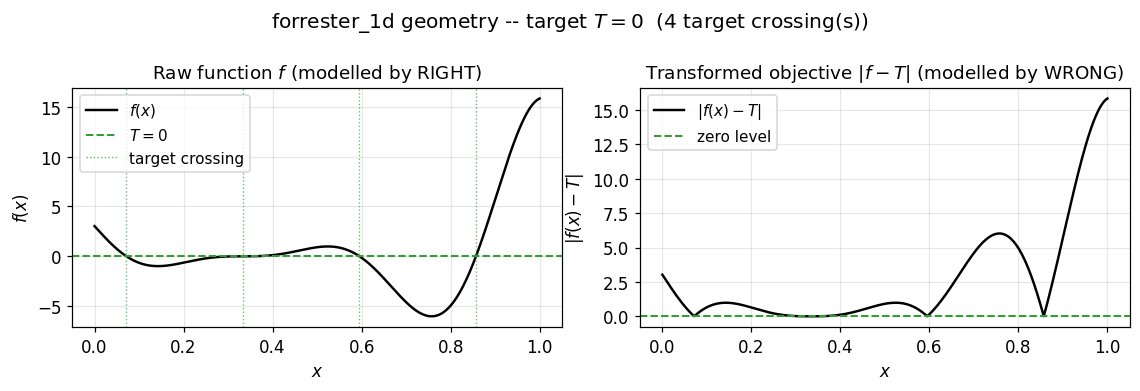

In [7]:
def _eval_f(X: np.ndarray) -> np.ndarray:
    """Evaluate the noiseless benchmark on an (n, dim) numpy array -> (n,)."""
    Xt = torch.as_tensor(X, dtype=torch.double)
    return benchmark.f(Xt).detach().cpu().numpy().reshape(-1)

if DIM == 1:
    lb, ub = float(benchmark.bounds[0, 0]), float(benchmark.bounds[1, 0])
    x_grid = np.linspace(lb, ub, 1001)
    f_grid = _eval_f(x_grid.reshape(-1, 1))
    abs_grid = np.abs(f_grid - T)

    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharex=True)
    ax = axes[0]
    ax.plot(x_grid, f_grid, color="black", lw=1.6, label=r"$f(x)$")
    ax.axhline(T, color="#2ca02c", ls="--", lw=1.3, label=fr"$T = {T:g}$")
    sign_change = np.where(np.diff(np.sign(f_grid - T)))[0]
    for k, idx in enumerate(sign_change):
        ax.axvline(x_grid[idx], color="#2ca02c", ls=":", lw=0.9, alpha=0.7,
                   label="target crossing" if k == 0 else None)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$")
    ax.set_title("Raw function $f$ (modelled by RIGHT)")
    ax.legend(loc="best")
    ax = axes[1]
    ax.plot(x_grid, abs_grid, color="black", lw=1.6, label=r"$|f(x)-T|$")
    ax.axhline(0.0, color="#2ca02c", ls="--", lw=1.3, label="zero level")
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$|f(x)-T|$")
    ax.set_title(r"Transformed objective $|f-T|$ (modelled by WRONG)")
    ax.legend(loc="best")
    fig.suptitle(f"{BENCHMARK} geometry -- target $T = {T:g}$  "
                 f"({len(sign_change)} target crossing(s))")
    fig.tight_layout()
    add_figure("01_geometry", fig)
    plt.show()

elif DIM == 2:
    lb = benchmark.bounds[0].detach().cpu().numpy()
    ub = benchmark.bounds[1].detach().cpu().numpy()
    n = 200
    xs = np.linspace(lb[0], ub[0], n)
    ys = np.linspace(lb[1], ub[1], n)
    XX, YY = np.meshgrid(xs, ys)
    F = _eval_f(np.column_stack([XX.ravel(), YY.ravel()])).reshape(n, n)
    A = np.abs(F - T)

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
    ax = axes[0]; ax.grid(False)
    cf = ax.contourf(XX, YY, F, levels=30, cmap="viridis")
    cl = ax.contour(XX, YY, F, levels=[T], colors="white", linewidths=1.8)
    fig.colorbar(cf, ax=ax, shrink=0.9)
    ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
    ax.set_title(f"Raw $f$ (modelled by RIGHT)\nwhite line: target set $f = {T:g}$")
    ax = axes[1]; ax.grid(False)
    cf = ax.contourf(XX, YY, A, levels=30, cmap="magma")
    ax.contour(XX, YY, A, levels=[0.0], colors="white", linewidths=1.2)
    fig.colorbar(cf, ax=ax, shrink=0.9)
    ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
    ax.set_title(r"Transformed $|f-T|$ (modelled by WRONG)")
    fig.suptitle(f"{BENCHMARK} geometry -- target $T = {T:g}$ "
                 f"(target match is a curve in 2D)")
    fig.tight_layout()
    add_figure("01_geometry", fig)
    plt.show()

else:
    f_sample = _eval_f(benchmark.test_set(4096, seed=0).detach().cpu().numpy())
    print(f"benchmark {BENCHMARK} has dim={DIM}; geometry plot skipped.")
    print(f"f range on a Sobol sample: [{f_sample.min():.4g}, {f_sample.max():.4g}], "
          f"target T = {T:g}")

## 2. Mechanism on one seed

We fix a single seed and watch, over BO iterations, (i) each surrogate's
posterior and (ii) the acquisition each surrogate induces. The point is to make
the SoC mechanism concrete: **the two posteriors are not two models of the same
function**. RIGHT's posterior is a model of $f$; WRONG's posterior is a model of
$|f - T|$. They live in different spaces and must not be overlaid.

These snapshots require a **1D benchmark with stored posterior predictions**. The
per-seed files store only `posterior_mean`/`posterior_std`, so we reconstruct the
test grid and the modelled ground truth from the benchmark
(`benchmark.test_set(...)` with the run's `test_grid.seed`). When predictions
were not stored (or the benchmark is multi-dimensional) this section is skipped.

In [8]:
POSTERIOR_SEED = 1
POSTERIOR_ITERS_REQUESTED = [5, 10, 20, 40, 50]

def seed_record_for(seed_idx: int) -> dict:
    """Per-seed processed record whose metadata.seed == seed_idx (fallback: positional)."""
    for s in all_seeds:
        if s.get("metadata", {}).get("seed") == seed_idx:
            return s
    return all_seeds[seed_idx]

def calibration_at(record: dict, method: str, iteration: int) -> Optional[dict]:
    for c in record["methods"][method]["calibrations"]:
        if c["iteration_index"] == iteration:
            return c
    return None

def reconstruct_test_grid() -> tuple[np.ndarray, np.ndarray]:
    """X_test (n_test, dim) and noiseless f(X_test), in benchmark order."""
    n_test = int(config["test_grid"]["n_test"])
    grid_seed = int(config["test_grid"].get("seed", 0))
    X_test = benchmark.test_set(n=n_test, seed=grid_seed)
    f_test = benchmark.f(X_test).detach().cpu().numpy().reshape(-1)
    return X_test.detach().cpu().numpy(), f_test

def modelled_truth(method: str, f_vals: np.ndarray) -> np.ndarray:
    """Ground truth in each surrogate's own modelled space."""
    if "wrong" in method:
        return np.abs(f_vals - T)      # WRONG models |f - T|
    return f_vals                      # RIGHT models f

def reconstruct_acquisition(method: str, mu: np.ndarray, sd: np.ndarray) -> np.ndarray:
    """alpha_RIGHT = -|mu - T| + sqrt(beta) sigma ;  alpha_WRONG = -mu + sqrt(beta) sigma."""
    if "wrong" in method:
        return -mu + np.sqrt(BETA) * sd
    return -np.abs(mu - T) + np.sqrt(BETA) * sd

_rec = seed_record_for(POSTERIOR_SEED)
CALIB_ITERS = [c["iteration_index"] for c in _rec["methods"][methods[0]]["calibrations"]]
POSTERIOR_ITERS = [it for it in POSTERIOR_ITERS_REQUESTED if it in CALIB_ITERS]
print("calibration checkpoints:", CALIB_ITERS)
print("posterior snapshots at :", POSTERIOR_ITERS if (DIM == 1 and PREDICTIONS_AVAILABLE) else "skipped")

calibration checkpoints: [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
posterior snapshots at : [5, 10, 20, 40, 50]


### 2.1 Posterior snapshots

Each row is one method's posterior ($\mu \pm 2\sigma$) against the truth it
models; the bottom row shows the induced acquisitions and their maximisers.

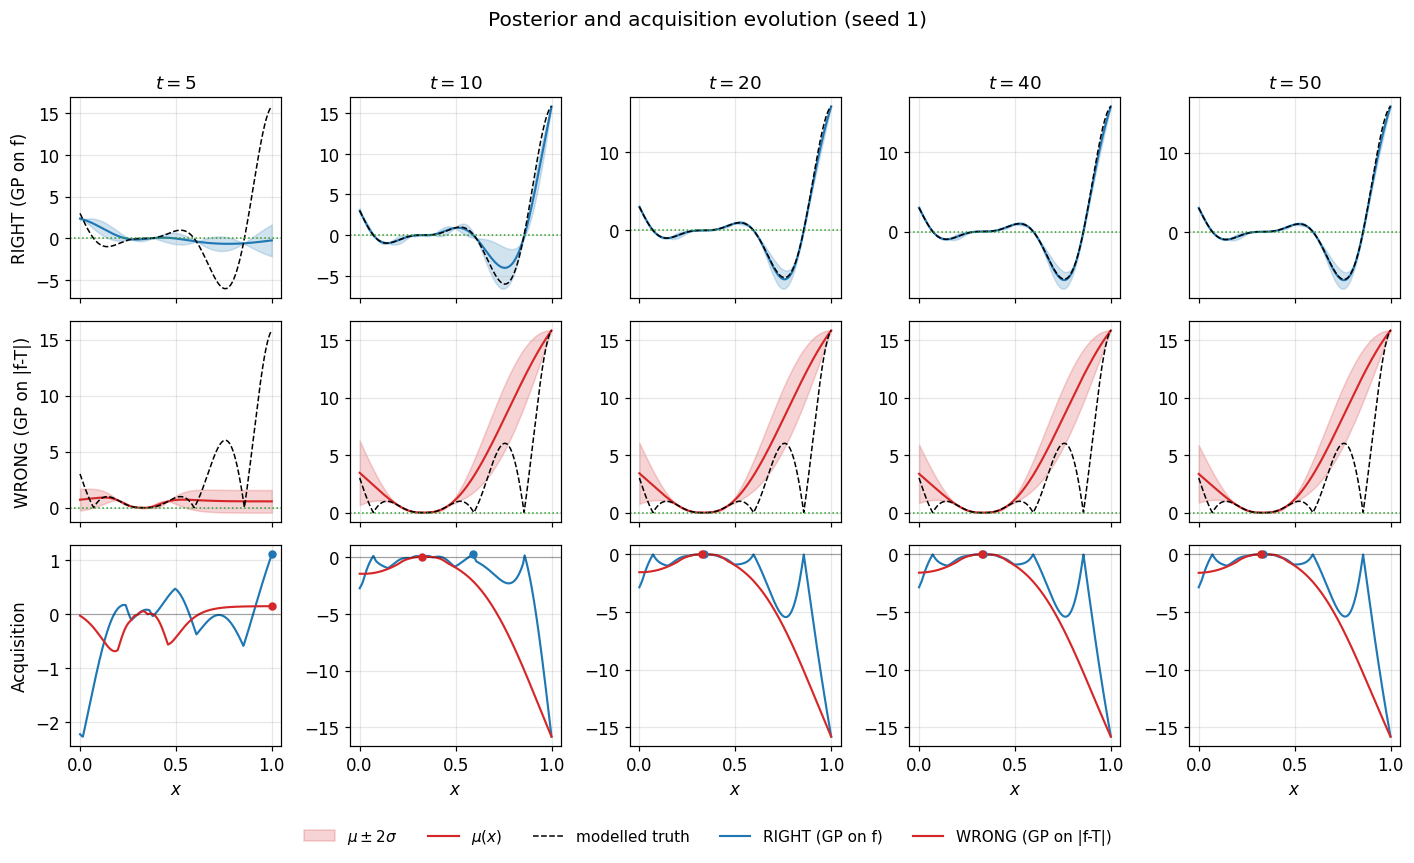

In [9]:
if DIM == 1 and PREDICTIONS_AVAILABLE and POSTERIOR_ITERS:
    record = seed_record_for(POSTERIOR_SEED)
    X_test, f_test = reconstruct_test_grid()
    x_test = X_test.reshape(-1)
    order = np.argsort(x_test)

    n_rows = len(methods) + 1   # one row per method + one acquisition row
    fig, axes = plt.subplots(
        n_rows, len(POSTERIOR_ITERS),
        figsize=(2.6 * len(POSTERIOR_ITERS), 2.6 * n_rows),
        sharex=True,
    )
    axes = np.atleast_2d(axes)
    acq_by_iter: dict = {}

    for i, method in enumerate(methods):
        style = style_for(method)
        truth = modelled_truth(method, f_test)
        for j, it in enumerate(POSTERIOR_ITERS):
            ax = axes[i, j]
            cal = calibration_at(record, method, it)
            pred = cal.get("predictions") if cal else None
            if not pred:
                ax.text(0.5, 0.5, f"no predictions\nat t={it}",
                        transform=ax.transAxes, ha="center", va="center")
                ax.set_axis_off()
                continue
            mu = np.asarray(pred["posterior_mean"]).reshape(-1)[order]
            sd = np.asarray(pred["posterior_std"]).reshape(-1)[order]
            xo = x_test[order]; yo = truth[order]
            ax.fill_between(xo, mu - 2 * sd, mu + 2 * sd, color=style["color"],
                            alpha=0.20, label=r"$\mu \pm 2\sigma$")
            ax.plot(xo, mu, color=style["color"], lw=1.4, label=r"$\mu(x)$")
            ax.plot(xo, yo, color="black", lw=1.0, ls="--", label="modelled truth")
            ax.axhline(T if "wrong" not in method else 0.0,
                       color="#2ca02c", ls=":", lw=1.0)
            acq_by_iter[(method, it)] = (xo, reconstruct_acquisition(method, mu, sd))
            if i == 0:
                ax.set_title(f"$t = {it}$")
            if j == 0:
                ax.set_ylabel(style["label"])

    acq_row = len(methods)
    for j, it in enumerate(POSTERIOR_ITERS):
        ax = axes[acq_row, j]
        for method in methods:
            if (method, it) not in acq_by_iter:
                continue
            style = style_for(method)
            xo, acq = acq_by_iter[(method, it)]
            ax.plot(xo, acq, color=style["color"], lw=1.4, label=style["label"])
            k = int(np.argmax(acq))
            ax.scatter(xo[k], acq[k], color=style["color"], s=20, zorder=3)
        ax.axhline(0.0, color="black", lw=0.8, alpha=0.3)
        if j == 0:
            ax.set_ylabel("Acquisition")
        ax.set_xlabel(r"$x$")

    handles, labels = [], []
    for ax in axes.ravel():
        h, l = ax.get_legend_handles_labels()
        handles.extend(h); labels.extend(l)
    unique = dict(zip(labels, handles))
    fig.legend(unique.values(), unique.keys(), loc="lower center",
               ncol=min(len(unique), 5), bbox_to_anchor=(0.5, -0.01), frameon=False)
    fig.suptitle(f"Posterior and acquisition evolution (seed {POSTERIOR_SEED})")
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    add_figure("02_posterior_and_acquisition_evolution", fig)
    plt.show()
else:
    print(f"posterior snapshots skipped "
          f"(DIM={DIM}, predictions_available={PREDICTIONS_AVAILABLE}).")

### 2.2 Acquisition snapshots

The acquisitions are drawn in the bottom row of the figure above, reconstructed
from the stored posteriors via
$\alpha_{\mathrm{RIGHT}} = -|\mu-T| + \sqrt{\beta}\,\sigma$ and
$\alpha_{\mathrm{WRONG}} = -\mu + \sqrt{\beta}\,\sigma$. The dot marks each
method's next query (the grid maximiser of its acquisition). When the section is
skipped the acquisitions cannot be reconstructed (no stored posteriors).

### 2.3 Interpretation of the mechanism

RIGHT must fit a *smooth* function and then reason about the level set
$\{f = T\}$ inside the acquisition; its uncertainty $\sigma_f$ is the honest
uncertainty about $f$. WRONG must fit the *kinked* $|f-T|$: near a target match
the true function has a non-differentiable cusp that a stationary-kernel GP
cannot represent, so the surrogate tends to round it off and misstate its
uncertainty exactly where the decision is most delicate. This is the qualitative
seed of the calibration differences quantified in Section 4.

## 3. Optimization performance across seeds

We now aggregate over all seeds. The running-best target distance after $t$
evaluations is

$$
D_t \;=\; \min_{1 \leq s \leq t} |f(x_s) - T|,
$$

which equals the target-matching simple regret $R_t^{\mathrm{target}}$ whenever
the target is attainable (oracle minimum zero).

### 3.1 Aggregation convention

Convergence curves come from `convergence_curves.json`. **We read the central
statistic, band type and confidence from the file itself** and build captions
from them, rather than hard-coding "mean" or "median".

In [10]:
conv = agg["convergence_curves"]
assert conv is not None, "convergence_curves.json missing — cannot plot convergence."
conv_iters = np.asarray(conv["iteration"])
CONV_N = conv.get("n_seeds", n_seeds)

print("convergence aggregation:",
      {k: conv.get(k) for k in ("statistic", "band_type", "confidence", "n_bootstrap")})

def plot_convergence_metric(ax, metric_key: str, logy: bool = False) -> Optional[dict]:
    """Plot center + band for `metric_key` for every method; returns one payload
    (for caption metadata) or None if the metric is absent."""
    sample = None
    for method in methods:
        payload = conv["methods"].get(method, {})
        if metric_key not in payload:
            print(f"[warn] {method}: convergence metric '{metric_key}' missing")
            continue
        cur = payload[metric_key]
        sample = sample or cur
        style = style_for(method)
        ax.plot(conv_iters, np.asarray(cur["center"]), color=style["color"], lw=1.8,
                label=style["label"])
        ax.fill_between(conv_iters, np.asarray(cur["lower"]), np.asarray(cur["upper"]),
                        color=style["color"], alpha=0.20)
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("iteration $t$")
    return sample

convergence aggregation: {'statistic': 'median', 'band_type': 'pointwise', 'confidence': 0.95, 'n_bootstrap': 10000}


### 3.2 Best-so-far target distance

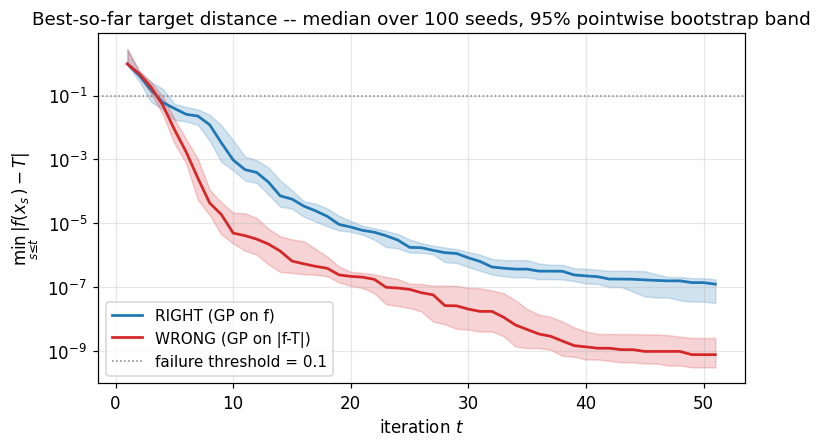

In [11]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
sample = plot_convergence_metric(ax, "running_best_target_distance", logy=True)
ax.set_ylabel(r"$\min_{s \leq t}\,|f(x_s) - T|$")
ft = config.get("failure_threshold")
if ft is not None:
    ax.axhline(ft, color="grey", ls=":", lw=1.0, label=f"failure threshold = {ft:g}")
ax.set_title("Best-so-far target distance -- " + band_caption(sample, CONV_N))
ax.legend(loc="best")
fig.tight_layout()
add_figure("03_running_best_target_distance", fig)
plt.show()

### 3.3 Instantaneous target distance / regret

The instantaneous target distance $|f(x_t) - T|$ at each iteration $t$ measures
how close the *queried* point is to the target, regardless of past best. It
exposes exploration behaviour that the running-best curve hides.

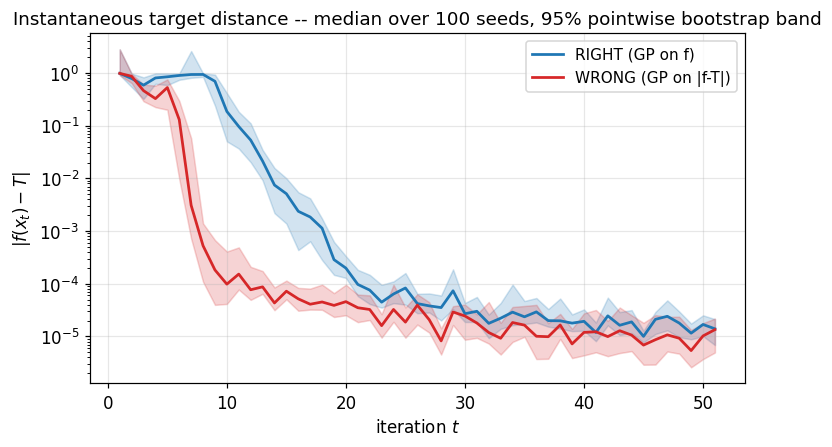

In [12]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
sample = plot_convergence_metric(ax, "instantaneous_target_distance", logy=True)
ax.set_ylabel(r"$|f(x_t) - T|$")
ax.set_title("Instantaneous target distance -- " + band_caption(sample, CONV_N))
ax.legend(loc="best")
fig.tight_layout()
add_figure("03_instantaneous_target_distance", fig)
plt.show()

### 3.4 Cumulative regret and AUC

The cumulative instantaneous regret $C_t = \sum_{s \leq t} |f(x_s) - T|$ and the
cumulative best-so-far regret penalise trajectories that linger far from the
target. The area under the running-best curve (`auc_running_target_regret`) is a
single-number summary of the whole trajectory; we report its across-seed
distribution from `final_performance.json`.

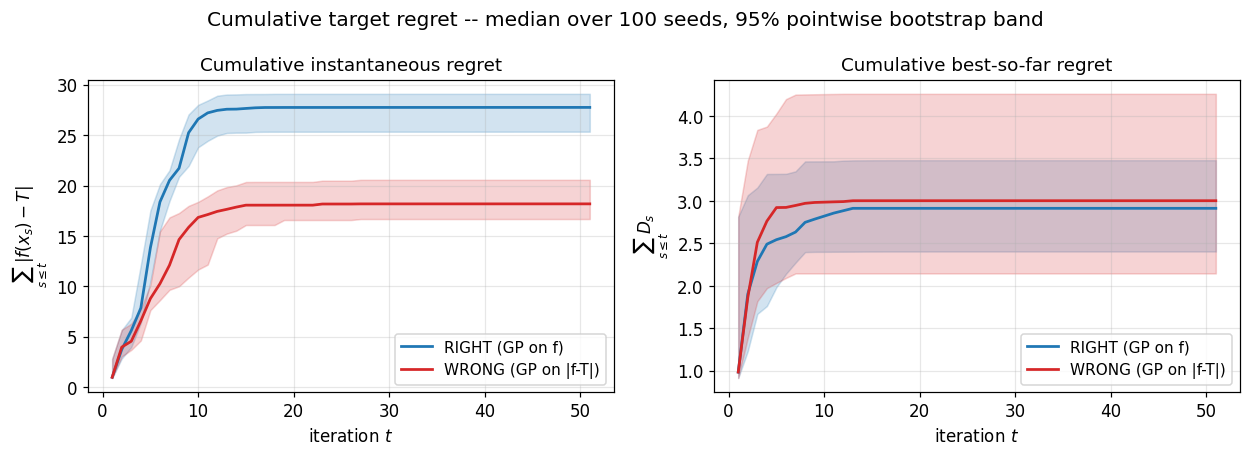

AUC of running target regret (across seeds):
                     median   IQR  mean   q90   q95
RIGHT (GP on f)        2.15 3.547 3.908 10.84 13.17
WRONG (GP on |f-T|)   2.244 3.424 3.213 7.812 10.57


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
s1 = plot_convergence_metric(axes[0], "cumulative_inst_target_regret")
axes[0].set_ylabel(r"$\sum_{s \leq t} |f(x_s)-T|$")
axes[0].set_title("Cumulative instantaneous regret")
axes[0].legend(loc="best")
s2 = plot_convergence_metric(axes[1], "cumulative_bsf_target_regret")
axes[1].set_ylabel(r"$\sum_{s \leq t} D_s$")
axes[1].set_title("Cumulative best-so-far regret")
axes[1].legend(loc="best")
fig.suptitle("Cumulative target regret -- " + band_caption(s1 or s2, CONV_N))
fig.tight_layout()
add_figure("03_cumulative_regret", fig)
plt.show()

fp = agg["final_performance"]
if fp is not None and "auc_running_target_regret" in fp["methods"][methods[0]]:
    rows = {}
    for m in methods:
        st = fp["methods"][m]["auc_running_target_regret"]
        rows[style_for(m)["label"]] = {
            "median": st["median"], "IQR": st["q75"] - st["q25"],
            "mean": st["mean"], "q90": st["q90"], "q95": st["q95"],
        }
    print("AUC of running target regret (across seeds):")
    print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.4g}"))

### 3.5 Final performance distribution

Beyond central tendency, the *spread* across seeds matters: a method can have a
good median yet a heavy tail of failures. We show the across-seed distribution of
two trajectory-level metrics on a log scale, with per-seed points overlaid.

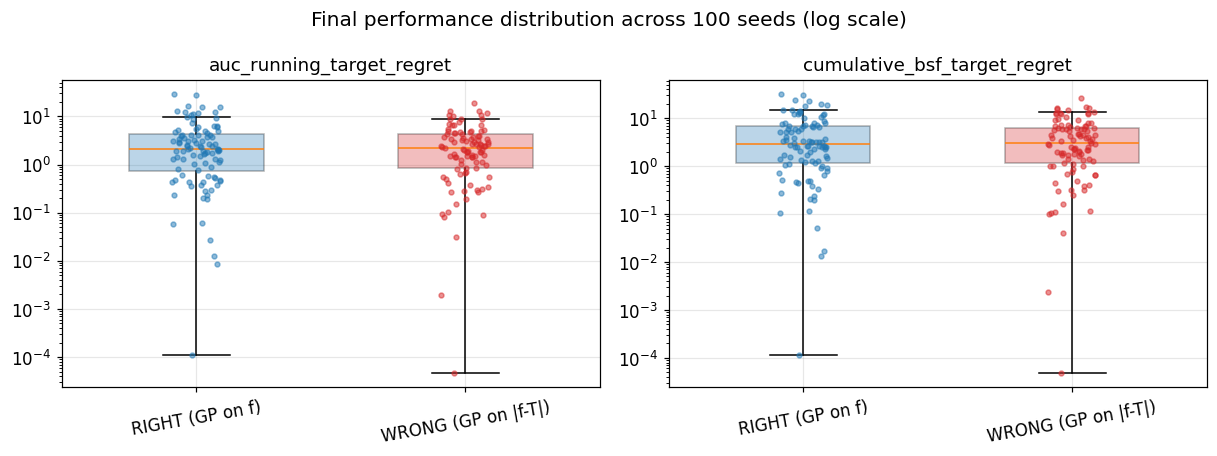

In [ ]:
def stack_final(metric: str) -> dict[str, np.ndarray]:
    """Per-seed final-metric values, one array per method."""
    return {m: np.array([s["methods"][m]["final"][metric] for s in all_seeds], float)
            for m in methods}

DIST_METRICS = ["cumulative_inst_target_regret", "cumulative_bsf_target_regret"]
fig, axes = plt.subplots(1, len(DIST_METRICS), figsize=(5.6 * len(DIST_METRICS), 4.2))
axes = np.atleast_1d(axes)
for ax, metric in zip(axes, DIST_METRICS):
    data = stack_final(metric)
    positions = np.arange(len(methods))
    vals = [np.clip(data[m], 1e-12, None) for m in methods]
    bp = ax.boxplot(vals, positions=positions, widths=0.5, showfliers=False,
                    patch_artist=True)
    for patch, m in zip(bp["boxes"], methods):
        patch.set_facecolor(style_for(m)["color"]); patch.set_alpha(0.30)
    for k, m in enumerate(methods):
        jitter = (np.random.default_rng(k).random(len(vals[k])) - 0.5) * 0.18
        ax.scatter(np.full_like(vals[k], k) + jitter, vals[k], s=10,
                   color=style_for(m)["color"], alpha=0.5, zorder=3)
    ax.set_yscale("log")
    ax.set_xticks(positions)
    ax.set_xticklabels([style_for(m)["label"] for m in methods], rotation=10)
    ax.set_title(metric)
fig.suptitle(f"Final performance distribution across {n_seeds} seeds (log scale)")
fig.tight_layout()
add_figure("03_final_distribution", fig)
plt.show()

### 3.6 Paired RIGHT-vs-WRONG comparison

RIGHT and WRONG share the same seed and initial design, so the comparison is
**paired**. We show a per-seed scatter of the final best target distance
$D_N$ and the histogram of the paired difference $D_N^{\mathrm{WRONG}} -
D_N^{\mathrm{RIGHT}}$ (positive favours RIGHT). The Wilcoxon signed-rank result
is read from `statistical_tests.json`.

> When the target is attainable and noiseless, *both* methods may drive $D_N$ to
> machine-epsilon; the paired difference is then near zero and the interesting
> separation lives in the cumulative / AUC metrics of §3.4&ndash;§3.5.

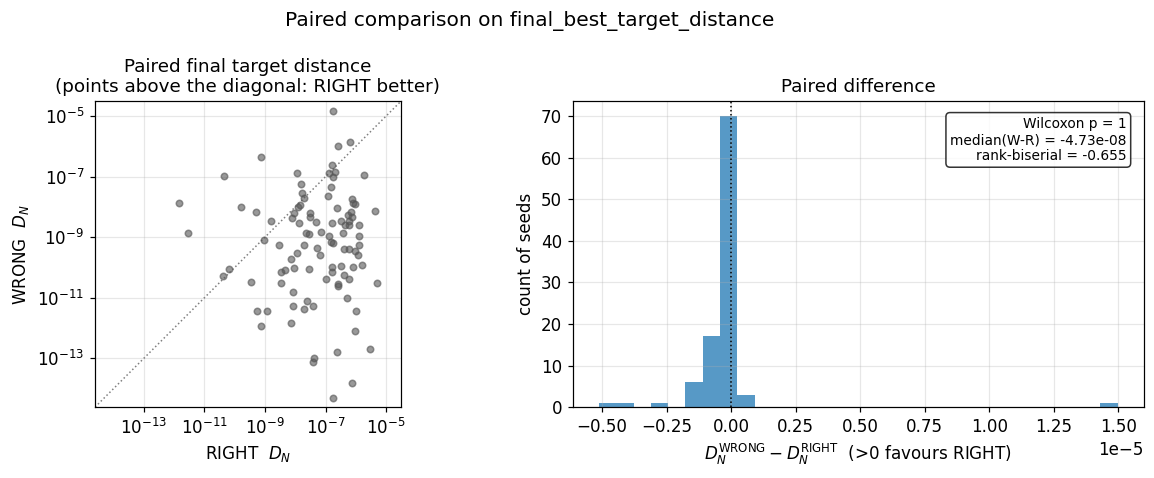

In [15]:
PAIR_METRIC = "final_best_target_distance"
if len(methods) == 2:
    right_m, wrong_m = methods[0], methods[1]
    if "right" in methods[1] and "wrong" in methods[0]:
        right_m, wrong_m = methods[1], methods[0]
    data = stack_final(PAIR_METRIC)
    r = np.clip(data[right_m], 1e-15, None)
    w = np.clip(data[wrong_m], 1e-15, None)

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
    ax = axes[0]
    lim_lo = min(r.min(), w.min()) * 0.5
    lim_hi = max(r.max(), w.max()) * 2.0
    ax.scatter(r, w, s=18, color="#555555", alpha=0.6, zorder=3)
    ax.plot([lim_lo, lim_hi], [lim_lo, lim_hi], color="grey", ls=":", lw=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(lim_lo, lim_hi); ax.set_ylim(lim_lo, lim_hi)
    ax.set_xlabel("RIGHT  $D_N$"); ax.set_ylabel("WRONG  $D_N$")
    ax.set_aspect("equal")
    ax.set_title("Paired final target distance\n(points above the diagonal: RIGHT better)")

    ax = axes[1]
    diff = data[wrong_m] - data[right_m]
    ax.hist(diff, bins=30, color="#1f77b4", alpha=0.75)
    ax.axvline(0.0, color="black", lw=1.0, ls=":")
    ax.set_xlabel(r"$D_N^{\mathrm{WRONG}} - D_N^{\mathrm{RIGHT}}$  (>0 favours RIGHT)")
    ax.set_ylabel("count of seeds")
    ax.set_title("Paired difference")

    st = agg["statistical_tests"]
    if st is not None:
        comp = st["comparisons"][0]
        payload = comp["metrics"].get(PAIR_METRIC)
        if payload is not None:
            wil = payload.get("wilcoxon_paired", {})
            txt = (f"Wilcoxon p = {wil.get('p_value'):.3g}\n"
                   f"median(W-R) = {wil.get('median_difference_wrong_minus_right'):.3g}\n"
                   f"rank-biserial = {payload.get('rank_biserial'):.3g}")
            ax.text(0.97, 0.95, txt, transform=ax.transAxes, ha="right", va="top",
                    fontsize=9, bbox=dict(boxstyle="round", fc="white", alpha=0.8))
    fig.suptitle(f"Paired comparison on {PAIR_METRIC}")
    fig.tight_layout()
    add_figure("03_paired_comparison", fig)
    plt.show()
else:
    print(f"paired comparison expects exactly 2 methods; found {methods}.")

### 3.7 Failure-rate analysis

A run *fails* when its final target distance exceeds `failure_threshold`. We
report the per-method failure rate (from `final_performance.json`) and, when
available, the per-metric failure rates from `statistical_tests.json`.

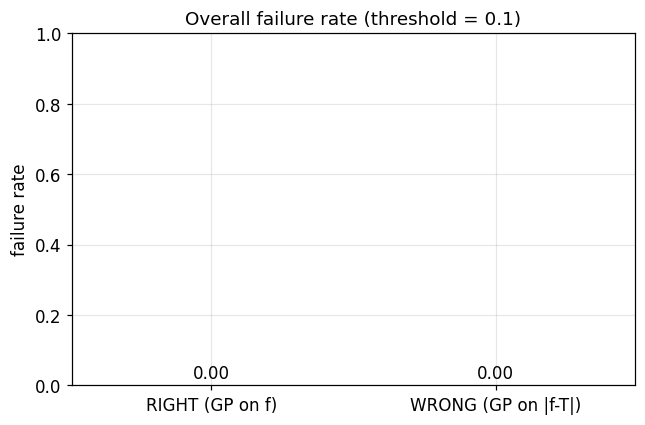

Per-metric failure rates (RIGHT vs WRONG):
                               right_failure_rate  wrong_failure_rate
metric                                                               
final_best_target_distance                      0                   0
final_target_simple_regret                      0                   0
mean_inst_target_distance                       1                0.99
worst_inst_target_distance                      1                   1
cumulative_inst_target_regret                   1                   1
cumulative_bsf_target_regret                 0.96                0.97
auc_running_target_regret                    0.94                0.94
hitting_time                                    1                   1


In [16]:
ft = config.get("failure_threshold")
fp = agg["final_performance"]
if ft is not None and fp is not None:
    rates = {style_for(m)["label"]: fp["methods"][m].get("failure_rate", np.nan)
             for m in methods}
    fig, ax = plt.subplots(figsize=(6.0, 4.0))
    labels = list(rates.keys())
    colors = [style_for(m)["color"] for m in methods]
    ax.bar(labels, [rates[l] for l in labels], color=colors, alpha=0.75)
    ax.set_ylim(0, 1.0)
    ax.set_ylabel("failure rate")
    ax.set_title(f"Overall failure rate (threshold = {ft:g})")
    for i, l in enumerate(labels):
        ax.text(i, rates[l] + 0.02, f"{rates[l]:.2f}", ha="center")
    fig.tight_layout()
    add_figure("03_failure_rate", fig)
    plt.show()

    st = agg["statistical_tests"]
    if st is not None:
        comp = st["comparisons"][0]
        rows = []
        for metric, payload in comp["metrics"].items():
            rows.append({
                "metric": metric,
                "right_failure_rate": payload.get("right_failure_rate"),
                "wrong_failure_rate": payload.get("wrong_failure_rate"),
            })
        print("Per-metric failure rates (RIGHT vs WRONG):")
        print(pd.DataFrame(rows).set_index("metric").to_string(float_format=lambda v: f"{v:.3g}"))
else:
    print("failure_threshold not set or final_performance missing — skipping.")

## 4. Probabilistic model diagnostics

Optimization performance answers *did it find a target match?* Calibration
answers *is the surrogate's uncertainty trustworthy?* These are distinct: a
method can optimise well yet be badly calibrated, or vice versa. Calibration is
always assessed **in each surrogate's own modelled space**: RIGHT against $f$,
WRONG against $|f-T|$. A direct numerical comparison of the two surrogates'
calibration is therefore only meaningful as a comparison of *how well each models
the object it chose to model*.

### 4.1 Aggregation convention for calibration curves

Calibration curves come from `calibration_curves.json`. Different metrics use
different bands: scalar location/coverage metrics use `calibration_band_type`,
while the standardized-residual metrics use `residual_band_type`. Each curve
carries its own `band_type`/`statistic`, surfaced in the captions.

> **Re-read the §0.4 caveat here:** for runs produced before the
> `bootstrap_uniform_band` fix, a uniform band labelled `statistic="median"` was
> centred on the *mean*. We therefore describe uniform bands as *simultaneous*
> envelopes and avoid claiming their centre is the declared statistic.

In [17]:
cal = agg["calibration_curves"]
assert cal is not None, "calibration_curves.json missing — cannot plot calibration."
CAL_N = cal.get("n_seeds", n_seeds)

def cal_iters(method: str) -> np.ndarray:
    return np.asarray(cal["methods"][method]["iteration"])

def has_cal(method: str, region: str, key: str) -> bool:
    return key in cal["methods"].get(method, {}).get(region, {})

def plot_cal_metric(ax, region: str, key: str, *, logy: bool = False,
                    nominal: Optional[float] = None) -> Optional[dict]:
    """Plot a calibration curve (center+band) for every method from the aggregate file."""
    sample = None
    for method in methods:
        block = cal["methods"].get(method, {}).get(region, {})
        if key not in block:
            continue
        payload = block[key]
        sample = sample or payload
        style = style_for(method)
        it = cal_iters(method)
        ax.plot(it, np.asarray(payload["center"]), color=style["color"], lw=1.8,
                label=style["label"])
        ax.fill_between(it, np.asarray(payload["lower"]), np.asarray(payload["upper"]),
                        color=style["color"], alpha=0.20)
    if nominal is not None:
        ax.axhline(nominal, color="grey", ls=":", lw=1.0, label=f"nominal {nominal:g}")
    if logy:
        ax.set_yscale("symlog")
    ax.set_xlabel("iteration $t$")
    return sample

print("calibration aggregation:",
      {k: cal.get(k) for k in ("statistic", "calibration_band_type", "residual_band_type", "n_bootstrap")})

calibration aggregation: {'statistic': 'median', 'calibration_band_type': 'pointwise', 'residual_band_type': 'uniform', 'n_bootstrap': 10000}


### 4.2 NLPD

The negative log predictive density,
$\mathrm{NLPD} = -\tfrac1m \sum_i \log p(y_i \mid \mu_i, \sigma_i^2)$, scores both
accuracy and uncertainty of the marginal predictions. Smaller is better. We show
NLPD on the full test grid and restricted to the near-target region.

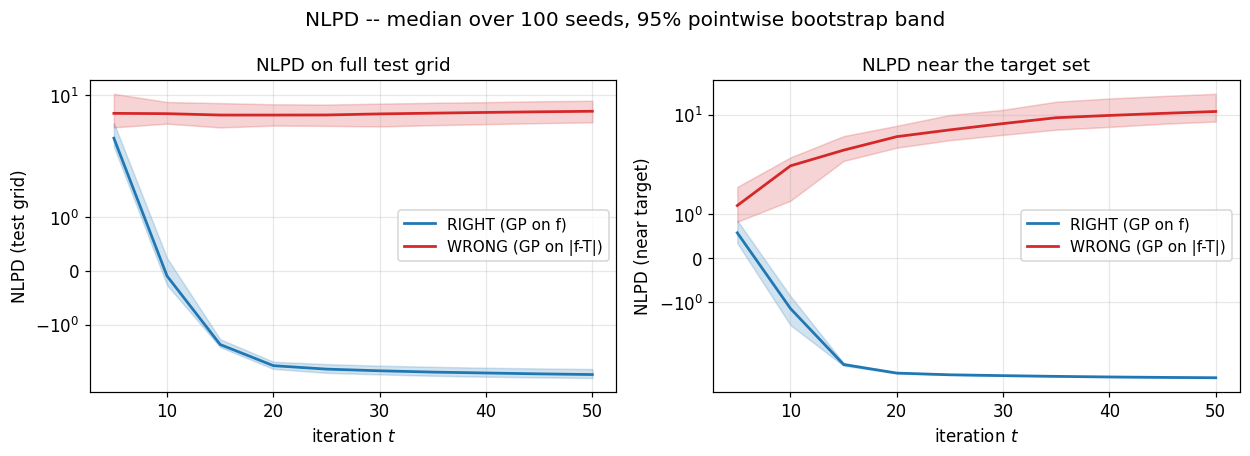

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
s1 = plot_cal_metric(axes[0], "global_calibration", "nlpd", logy=True)
axes[0].set_ylabel("NLPD (test grid)")
axes[0].set_title("NLPD on full test grid")
axes[0].legend(loc="best")
s2 = plot_cal_metric(axes[1], "near_target", "nlpd", logy=True)
axes[1].set_ylabel("NLPD (near target)")
axes[1].set_title("NLPD near the target set")
axes[1].legend(loc="best")
fig.suptitle("NLPD -- " + band_caption(s1 or s2, CAL_N))
fig.tight_layout()
add_figure("04_nlpd", fig)
plt.show()

### 4.3 UCB coverage and confidence violation rate

Empirical coverage of the nominal $95\%$ interval should sit near $0.95$; lower
means overconfidence. The confidence violation rate measures how often the truth
falls outside the $\beta$-confidence band actually used by the acquisition.

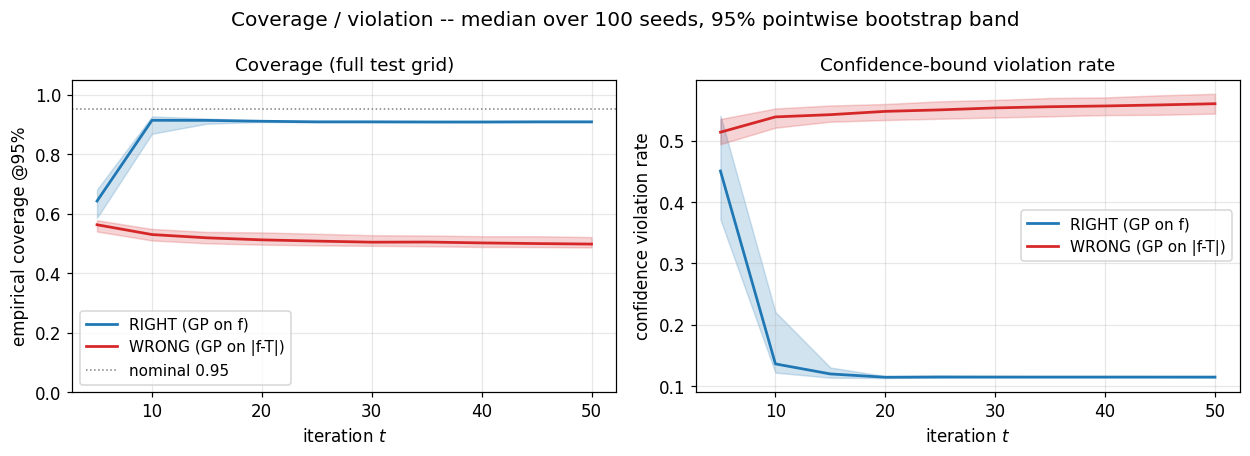

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
s1 = plot_cal_metric(axes[0], "global_calibration", "coverage", nominal=0.95)
axes[0].set_ylim(0.0, 1.05); axes[0].set_ylabel("empirical coverage @95%")
axes[0].set_title("Coverage (full test grid)")
axes[0].legend(loc="best")
s2 = plot_cal_metric(axes[1], "global_calibration", "confidence_violation_rate")
axes[1].set_ylabel("confidence violation rate")
axes[1].set_title("Confidence-bound violation rate")
axes[1].legend(loc="best")
fig.suptitle("Coverage / violation -- " + band_caption(s1 or s2, CAL_N))
fig.tight_layout()
add_figure("04_coverage_violation", fig)
plt.show()

### 4.4 Standardized residuals

The standardized residuals $z_i = (y_i - \mu_i)/\sigma_i$ should be $\mathcal{N}(0,1)$
if the predictive variances are right: mean $\approx 0$, std $\approx 1$,
mean-absolute $\approx \sqrt{2/\pi} \approx 0.8$. These curves typically use the
`residual_band_type` (often a *uniform / simultaneous* band).

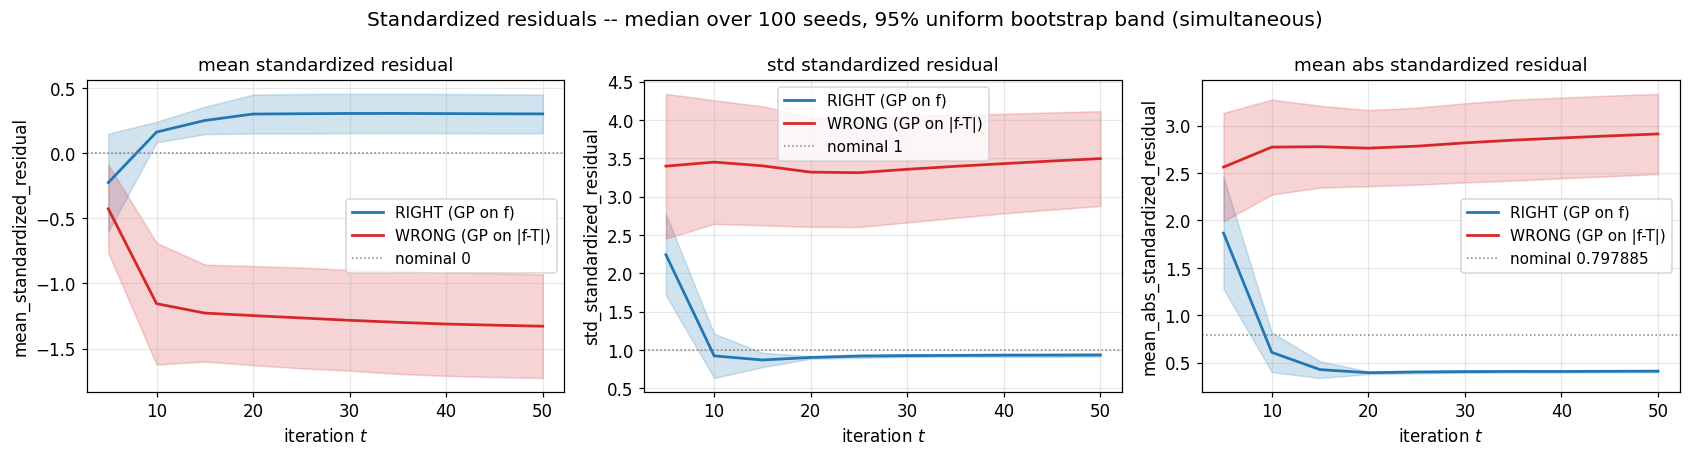

In [20]:
res_keys = ["mean_standardized_residual", "std_standardized_residual",
            "mean_abs_standardized_residual"]
ref_lines = {"mean_standardized_residual": 0.0, "std_standardized_residual": 1.0,
             "mean_abs_standardized_residual": float(np.sqrt(2 / np.pi))}
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
sample = None
for ax, key in zip(axes, res_keys):
    s = plot_cal_metric(ax, "global_calibration", key, nominal=ref_lines[key])
    sample = sample or s
    ax.set_ylabel(key); ax.set_title(key.replace("_", " "))
    ax.legend(loc="best")
fig.suptitle("Standardized residuals -- " + band_caption(sample, CAL_N))
fig.tight_layout()
add_figure("04_standardized_residuals", fig)
plt.show()

### 4.5 PIT diagnostics

The probability integral transform $\mathrm{PIT}_i = \Phi(z_i)$ is uniform on
$[0,1]$ for a calibrated model (so $\overline{\mathrm{PIT}} \approx 0.5$,
$\mathrm{sd}(\mathrm{PIT}) \approx 1/\sqrt{12} \approx 0.289$). We show the
across-seed trajectories of the PIT mean/std (aggregate file) and, when posterior
predictions were stored, a pooled PIT histogram at the final checkpoint.

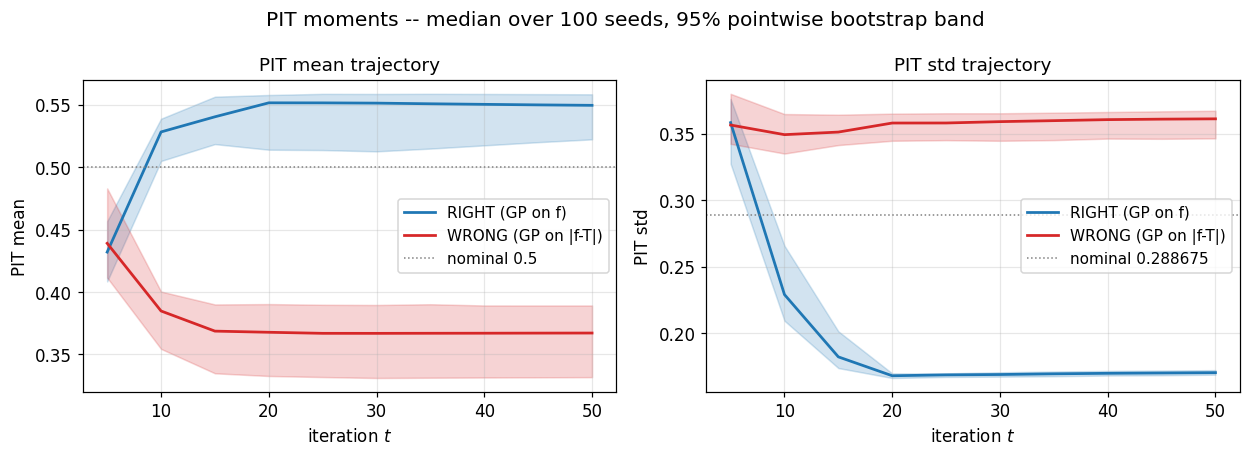

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
s1 = plot_cal_metric(axes[0], "global_calibration", "pit_mean", nominal=0.5)
axes[0].set_ylabel("PIT mean"); axes[0].set_title("PIT mean trajectory")
axes[0].legend(loc="best")
s2 = plot_cal_metric(axes[1], "global_calibration", "pit_std",
                     nominal=float(1 / np.sqrt(12)))
axes[1].set_ylabel("PIT std"); axes[1].set_title("PIT std trajectory")
axes[1].legend(loc="best")
fig.suptitle("PIT moments -- " + band_caption(s1 or s2, CAL_N))
fig.tight_layout()
add_figure("04_pit_moments", fig)
plt.show()

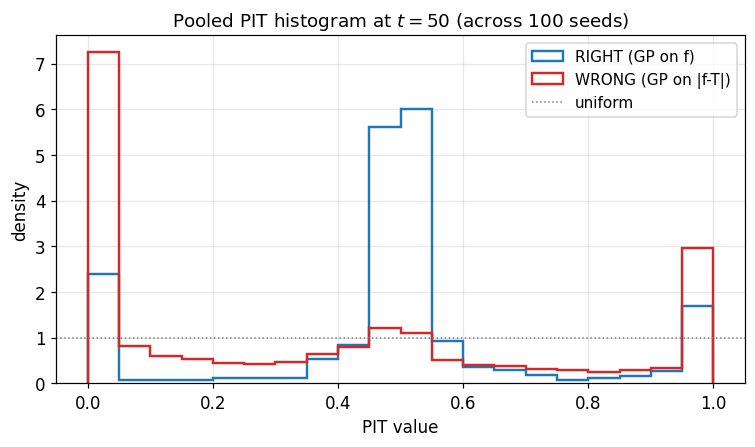

In [22]:
PIT_ITERATION = int(cal_iters(methods[0])[-1])

def pooled_standardized_residuals(method: str, iteration: int,
                                  f_test: np.ndarray) -> np.ndarray:
    """(y - mu)/sigma pooled across seeds, with y in the method's modelled space."""
    truth = modelled_truth(method, f_test)
    zs = []
    for s in all_seeds:
        c = next((c for c in s["methods"][method]["calibrations"]
                  if c["iteration_index"] == iteration), None)
        pred = c.get("predictions") if c else None
        if not pred:
            continue
        mu = np.asarray(pred["posterior_mean"])
        sd = np.clip(np.asarray(pred["posterior_std"]), 1e-12, None)
        zs.append((truth - mu) / sd)
    return np.concatenate(zs) if zs else np.array([])

if PREDICTIONS_AVAILABLE:
    _, f_test_full = reconstruct_test_grid()
    fig, ax = plt.subplots(figsize=(7.0, 4.2))
    bins = np.linspace(0.0, 1.0, 21)
    for method in methods:
        z = pooled_standardized_residuals(method, PIT_ITERATION, f_test_full)
        if z.size == 0:
            continue
        ax.hist(norm.cdf(z), bins=bins, density=True, histtype="step", lw=1.6,
                color=style_for(method)["color"], label=style_for(method)["label"])
    ax.axhline(1.0, color="grey", ls=":", lw=1.0, label="uniform")
    ax.set_xlabel("PIT value"); ax.set_ylabel("density")
    ax.set_title(f"Pooled PIT histogram at $t = {PIT_ITERATION}$ (across {n_seeds} seeds)")
    ax.legend(loc="best")
    fig.tight_layout()
    add_figure("04_pit_histogram", fig)
    plt.show()
else:
    print("pooled PIT histogram skipped (no stored posterior predictions).")

### 4.6 QQ diagnostics

The QQ plot compares empirical quantiles of the pooled standardized residuals
against $\mathcal{N}(0,1)$ quantiles. Calibrated residuals lie on the diagonal;
curvature or tail departures reveal misspecified predictive variance. Requires
stored posterior predictions.

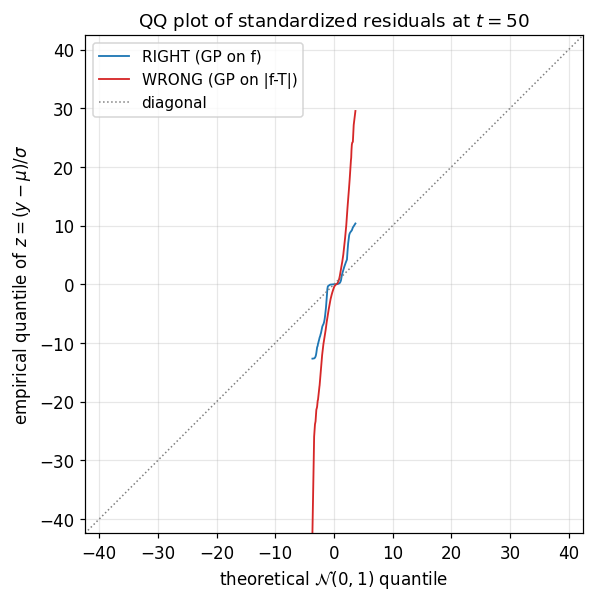

In [23]:
if PREDICTIONS_AVAILABLE:
    _, f_test_full = reconstruct_test_grid()
    fig, ax = plt.subplots(figsize=(5.6, 5.6))
    qq_extreme = 0.0
    for method in methods:
        z = pooled_standardized_residuals(method, PIT_ITERATION, f_test_full)
        if z.size == 0:
            continue
        z_sorted = np.sort(z)
        if z_sorted.size > 4000:
            idx = np.linspace(0, z_sorted.size - 1, 4000).astype(int)
            z_sorted = z_sorted[idx]
        probs = (np.arange(1, z_sorted.size + 1) - 0.5) / z_sorted.size
        theo = norm.ppf(probs)
        ax.plot(theo, z_sorted, lw=1.2, color=style_for(method)["color"],
                label=style_for(method)["label"])
        qq_extreme = max(qq_extreme, float(np.max(np.abs(z_sorted))), float(np.max(np.abs(theo))))
    lim = max(qq_extreme, 4.0)
    ax.plot([-lim, lim], [-lim, lim], color="grey", ls=":", lw=1.0, label="diagonal")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel(r"theoretical $\mathcal{N}(0,1)$ quantile")
    ax.set_ylabel(r"empirical quantile of $z = (y-\mu)/\sigma$")
    ax.set_title(f"QQ plot of standardized residuals at $t = {PIT_ITERATION}$")
    ax.legend(loc="best")
    fig.tight_layout()
    add_figure("04_qq", fig)
    plt.show()
else:
    print("QQ plot skipped (no stored posterior predictions).")

### 4.7 Near-target calibration

Calibration *where the decision is made* matters more than average calibration.
We restrict coverage and the violation rate to the near-target region
($|f - T| \le \varepsilon$). This is the region the acquisition actually queries,
so miscalibration here directly degrades decisions.

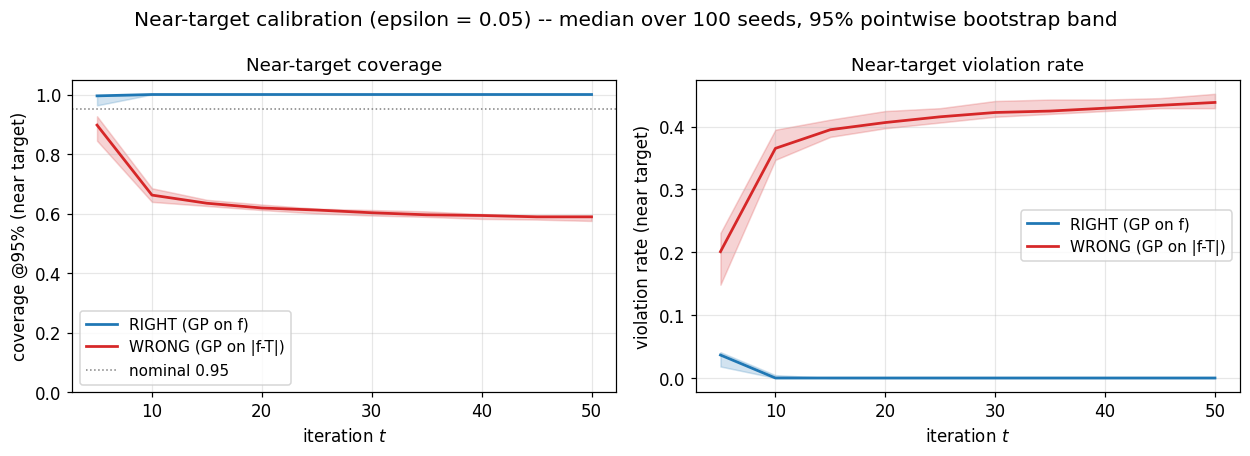

In [24]:
if any(has_cal(m, "near_target", "coverage") for m in methods):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    s1 = plot_cal_metric(axes[0], "near_target", "coverage", nominal=0.95)
    axes[0].set_ylim(0.0, 1.05); axes[0].set_ylabel("coverage @95% (near target)")
    axes[0].set_title("Near-target coverage")
    axes[0].legend(loc="best")
    s2 = plot_cal_metric(axes[1], "near_target", "confidence_violation_rate")
    axes[1].set_ylabel("violation rate (near target)")
    axes[1].set_title("Near-target violation rate")
    axes[1].legend(loc="best")
    eps = config.get("near_target_epsilon")
    fig.suptitle(f"Near-target calibration (epsilon = {eps:g}) -- " + band_caption(s1 or s2, CAL_N))
    fig.tight_layout()
    add_figure("04_near_target_calibration", fig)
    plt.show()
else:
    print("near-target calibration curves not available — skipping.")

### 4.8 Joint posterior diagnostics

The marginal diagnostics above ignore cross-point correlations. The joint
diagnostics evaluate the full Gaussian on a small joint test set:
`nlpd_joint` (joint NLPD), `mahalanobis_sq` (squared Mahalanobis distance, whose
expectation is the joint dimension if calibrated), and `logdet` (log-determinant
of the predictive covariance). Shown only when present.

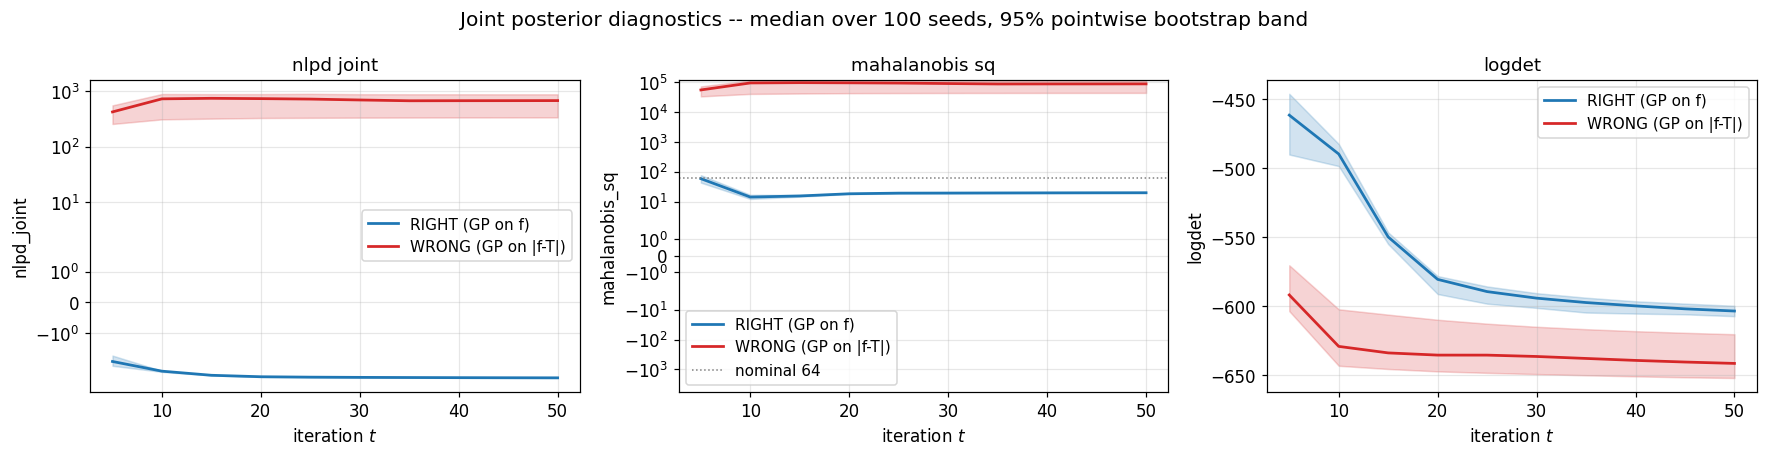

In [25]:
joint_keys = ["nlpd_joint", "mahalanobis_sq", "logdet"]
present = [k for k in joint_keys if any(has_cal(m, "joint_posterior", k) for m in methods)]
if present:
    fig, axes = plt.subplots(1, len(present), figsize=(5.4 * len(present), 4.2))
    axes = np.atleast_1d(axes)
    sample = None
    m_joint = config.get("test_grid", {}).get("m_test_joint_distrib")
    for ax, key in zip(axes, present):
        nominal = float(m_joint) if (key == "mahalanobis_sq" and m_joint) else None
        s = plot_cal_metric(ax, "joint_posterior", key, logy=(key != "logdet"),
                            nominal=nominal)
        sample = sample or s
        ax.set_ylabel(key); ax.set_title(key.replace("_", " "))
        ax.legend(loc="best")
    fig.suptitle("Joint posterior diagnostics -- " + band_caption(sample, CAL_N))
    fig.tight_layout()
    add_figure("04_joint_posterior", fig)
    plt.show()
else:
    print("joint posterior diagnostics not available — skipping.")

## 5. Summary of findings

We close by separating two questions that are easy to conflate: *how well did
each method optimise?* and *how trustworthy was each surrogate?* The cell below
assembles a compact, reproducible summary table from the loaded files; the
narrative subsections interpret it without over-claiming.

In [26]:
rows = []
fp = agg["final_performance"]; st = agg["statistical_tests"]
summary_metrics = ["final_best_target_distance", "auc_running_target_regret",
                   "cumulative_bsf_target_regret"]
for metric in summary_metrics:
    rec = {"metric": metric}
    if fp is not None:
        for m in methods:
            tag = "RIGHT" if "right" in m else ("WRONG" if "wrong" in m else m)
            rec[f"{tag}_median"] = fp["methods"][m][metric]["median"]
    if st is not None:
        payload = st["comparisons"][0]["metrics"].get(metric, {})
        rec["wilcoxon_p"] = payload.get("wilcoxon_paired", {}).get("p_value")
        rec["rank_biserial"] = payload.get("rank_biserial")
    rows.append(rec)
summary_df = pd.DataFrame(rows).set_index("metric")
print("Reproducible summary (medians + paired test):")
print(summary_df.to_string(float_format=lambda v: f"{v:.4g}"))

Reproducible summary (medians + paired test):
                              RIGHT_median  WRONG_median  wilcoxon_p  rank_biserial
metric                                                                             
final_best_target_distance       1.232e-07     7.612e-10           1        -0.6546
auc_running_target_regret             2.15         2.244      0.8243        -0.0118
cumulative_bsf_target_regret         2.913         3.003      0.8243        -0.0126


### 5.1 Optimization takeaway

When the target is attainable, both methods can ultimately locate a target match,
so the *final* best-target-distance is often a poor discriminator (read it
together with its across-seed spread in §3.5). The trajectory-level metrics
&mdash; instantaneous distance, cumulative regret and AUC &mdash; are where any
real difference in sample efficiency appears. Interpret the paired Wilcoxon
$p$-value in `summary_df` with the sign convention *positive rank-biserial favours
RIGHT*; do not over-read a single benchmark/run.

### 5.2 Calibration takeaway

Calibration is judged in each surrogate's own modelled space. RIGHT models the
smooth $f$ and so tends to produce residuals closer to $\mathcal{N}(0,1)$ and
coverage nearer the nominal level, especially in the near-target region that
drives decisions (§4.3, §4.7). WRONG must fit the kinked $|f-T|$, which a
stationary GP cannot represent at the cusp; the marginal and joint diagnostics
(§4.2&ndash;§4.8) typically expose this as inflated NLPD, biased residuals and
larger Mahalanobis distances. Treat uniform-band trajectories as *simultaneous
envelopes* per the §0.4/§4.1 caveat.

### 5.3 Separation-of-concerns interpretation

The two methods differ not by a hyperparameter but by **the statistical object
they model**. RIGHT keeps the GP a faithful model of the unknown phenomenon $f$
and places the target $T$ in the decision rule, where it belongs; WRONG folds the
task ($T$) into the learning target, forcing the surrogate to model a
task-specific, non-smooth transform of $f$. Separation of Concerns predicts that
keeping the model generic and pushing task structure into the acquisition yields
a better-calibrated surrogate without sacrificing &mdash; and often improving
&mdash; optimization behaviour. The figures above are the evidence for that thesis
on this benchmark.

## Save all figures

Every figure registered in `FIGURES` is written to `FIG_DIR` as both `.png` and
`.pdf`, and the saved paths are listed in a DataFrame. This is the *only* cell
that writes figures to disk.

In [ ]:
saved = []
for name, fig in FIGURES.items():
    png = FIG_DIR / f"{name}.png"
    pdf = FIG_DIR / f"{name}.pdf"
    fig.savefig(png)
    fig.savefig(pdf)
    saved.append({"figure": name,
                  "png": str(png.relative_to(RUN_DIR)),
                  "pdf": str(pdf.relative_to(RUN_DIR))})

if agg["statistical_tests"] is not None:
    comp = agg["statistical_tests"]["comparisons"][0]
    rows = []
    for metric, payload in comp["metrics"].items():
        rows.append({
            "metric": metric,
            "wilcoxon_p": payload.get("wilcoxon_paired", {}).get("p_value"),
            "mann_whitney_p": payload.get("mann_whitney", {}).get("p_value"),
            "rank_biserial": payload.get("rank_biserial"),
            "cohens_d_right_better": payload.get("cohens_d_right_better"),
            "right_failure_rate": payload.get("right_failure_rate"),
            "wrong_failure_rate": payload.get("wrong_failure_rate"),
        })
    out_csv = FIG_DIR / "final_performance_comparison.csv"
    pd.DataFrame(rows).set_index("metric").to_csv(out_csv)
    print(f"saved comparison table: {out_csv.relative_to(RUN_DIR)}")

saved_df = pd.DataFrame(saved)
print(f"saved {len(saved)} figures to {FIG_DIR}")
saved_df